# 09 · Measurement uncertainty and the small-width bias (Table *uncertainty*, Sec. *Systematic bias*, R1.4 / R2.2)

1. **Uncertainty table**: per-target mean ± U₉₅ (U₉₅ = 2σ) from the Table 1 captures, as in the revision draft.
2. **Additive edge error**: a constant offset in pixels explains why ET-1 has the largest *relative* error.
3. **Sub-pixel edges**: on the sweep's reference-pose captures, sub-pixel edge localisation versus integer edges.

| | |
|---|---|
| **Inputs** | `data/raw/table1_et/`, `data/raw/robustness/` |
| **Outputs** | `results/tables/uncertainty.csv`, `uncertainty.tex`, `subpixel_bias.csv`; `results/figures/fig_bias.png` |
| **Runtime** | ~20 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


## 1 · Uncertainty from the Table 1 captures

In [ ]:
caps, _ = vc.load_table1()
roi = vc.preview_roi((2160, 3840), (430, 932))
GT = np.array(vc.ET_GT_MM)
R = np.array([vc.measure_capture(vc.read_rgb(p), b, roi).widths_mm for p, b in zip(caps.path, caps.bbox)]).round(3)
from visioncrack.metrics import half_up
mean, sd = half_up(R.mean(0), 3), half_up(R.std(0), 3)   # as printed in Table 1
U95 = 2 * sd                                             # k = 2
unc = pd.DataFrame({'GT_mm': GT, 'mean_mm': mean, 'bias_mm': (mean - GT).round(3),
                    'U95_mm': U95.round(3), 'rel_bias_%': (100 * (mean - GT) / GT).round(1)},
                   index=[f'ET-{i+1}' for i in range(5)])
unc.loc['Overall'] = [np.nan, np.nan, np.abs(unc.bias_mm).mean(), U95.mean(), np.nan]
unc.to_csv(TAB / 'uncertainty.csv', float_format='%.4f')
unc

,GT_mm,mean_mm,bias_mm,U95_mm,rel_bias_%
ET-1,0.55,0.652,0.1020,0.0100,18.5
ET-2,1.10,1.066,-0.0340,0.0000,-3.1
ET-3,1.65,1.745,0.0950,0.0260,5.8
ET-4,2.20,2.209,0.0090,0.0260,0.4
ET-5,2.75,2.814,0.0640,0.0240,2.3
Overall,NaN,NaN,0.0608,0.0172,NaN


In [ ]:
draft_U95 = [0.010, 0.001, 0.026, 0.026, 0.024]
assert np.allclose(unc.iloc[:5].bias_mm, [0.102, -0.034, 0.095, 0.009, 0.064])
assert np.allclose(unc.iloc[:5]['rel_bias_%'], [18.5, -3.1, 5.8, 0.4, 2.3])
assert round(unc.loc['Overall', 'U95_mm'], 3) == 0.017
diff = np.round(unc.iloc[:5].U95_mm.values - draft_U95, 3)
print('✓ bias, relative bias and overall U95 match the draft')
print('U95 differences vs draft:', dict(zip(unc.index[:5], diff)),
      '→ ET-2 is 0.000 here (all 10 readings identical); the draft prints 0.001')

✓ bias, relative bias and overall U95 match the draft
U95 differences vs draft: {'ET-1': np.float64(0.0), 'ET-2': np.float64(-0.001), 'ET-3': np.float64(0.0), 'ET-4': np.float64(0.0), 'ET-5': np.float64(0.0)} → ET-2 is 0.000 here (all 10 readings identical); the draft prints 0.001


In [ ]:
rows = [f"{t} & {g:.2f} & ${m:.3f} \\pm {u:.3f}$ & ${b:+.3f}$ & {u:.3f} & ${rb:+.1f}$ \\\\"
        for t, (g, m, b, u, rb) in zip(['T1', 'T2', 'T3', 'T4', 'T5'], unc.iloc[:5].values)]
rows += ['\\midrule', f"\\textbf{{Overall}} & -- & -- & \\textbf{{{unc.loc['Overall','bias_mm']:.3f}}} & "
         f"\\textbf{{{unc.loc['Overall','U95_mm']:.3f}}} & -- \\\\"]
(TAB / 'uncertainty.tex').write_text('\n'.join(rows)); print((TAB / 'uncertainty.tex').read_text())

T1 & 0.55 & $0.652 \pm 0.010$ & $+0.102$ & 0.010 & $+18.5$ \\
T2 & 1.10 & $1.066 \pm 0.000$ & $-0.034$ & 0.000 & $-3.1$ \\
T3 & 1.65 & $1.745 \pm 0.026$ & $+0.095$ & 0.026 & $+5.8$ \\
T4 & 2.20 & $2.209 \pm 0.026$ & $+0.009$ & 0.026 & $+0.4$ \\
T5 & 2.75 & $2.814 \pm 0.024$ & $+0.064$ & 0.024 & $+2.3$ \\
\midrule
\textbf{Overall} & -- & -- & \textbf{0.061} & \textbf{0.017} & -- \\


## 2 · Additive edge error
If binarization adds a roughly constant δ to every width, then bias ≈ δ for all targets and the relative bias ≈ δ / GT.
That is large at 0.55 mm and small at 2.75 mm. Below, the bias is shown in pixels next to the error a constant offset would give.

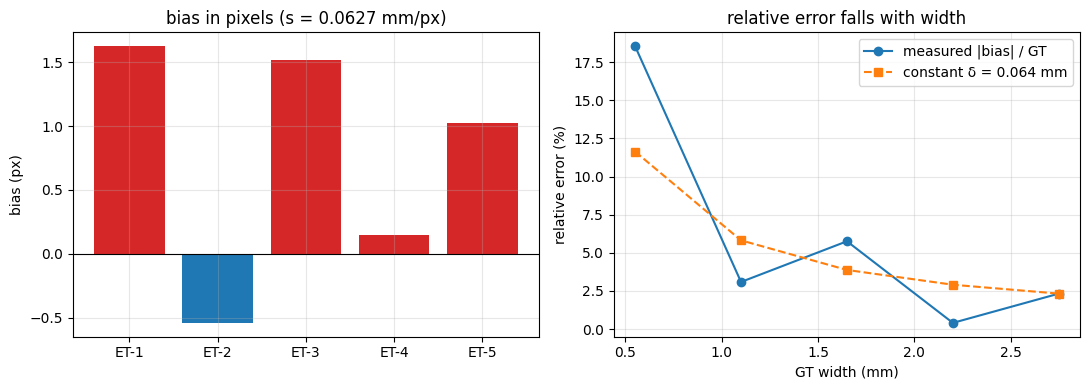

bias (px): [ 1.63 -0.54  1.51  0.14  1.02]


In [ ]:
s = vc.mm_per_px(roi.w)
bias_px = (mean - GT) / s
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(unc.index[:5], bias_px, color=['#d62728' if b > 0 else '#1f77b4' for b in bias_px])
ax[0].axhline(0, color='k', lw=.8); ax[0].set(ylabel='bias (px)', title=f'bias in pixels (s = {s:.4f} mm/px)')
d = np.median(np.abs(bias_px)) * s
ax[1].plot(GT, 100 * np.abs(mean - GT) / GT, 'o-', label='measured |bias| / GT')
ax[1].plot(GT, 100 * d / GT, 's--', label=f'constant δ = {d:.3f} mm')
ax[1].set(xlabel='GT width (mm)', ylabel='relative error (%)', title='relative error falls with width'); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / 'fig_bias.png', dpi=200); plt.show()
print('bias (px):', bias_px.round(2))

## 3 · Integer vs. sub-pixel edges (sweep, reference pose)
This uses the sweep's measurement chain: 4 *norm* captures, with the scale taken from the barcode. Edges are refined to the 50 %-of-peak
crossing of each bar's darkness profile. Note that this setup is not the Table 1 pipeline: here the integer-edge bias is *negative*.
Whether to adopt sub-pixel edges in the main pipeline is an open decision.

In [ ]:
from visioncrack import sweep
res, _ = sweep.run_all()
nm = res[(res.folder == 'norm') & res.ref_found]
b_int = np.vstack(nm.ref_mm).mean(0) - GT
b_sub = np.vstack(nm.ref_mm_sub).mean(0) - GT
sb = pd.DataFrame({'GT_mm': GT, 'bias_integer_mm': b_int.round(3), 'bias_subpixel_mm': b_sub.round(3)},
                  index=[f'ET-{i+1}' for i in range(5)])
sb.loc['MAE'] = [np.nan, np.abs(b_int).mean(), np.abs(b_sub).mean()]
sb.to_csv(TAB / 'subpixel_bias.csv', float_format='%.4f')
assert np.allclose(sb.iloc[:5].bias_integer_mm, [-0.084, -0.051, -0.045, -0.090, -0.032], atol=0.0015)
assert round(b_sub[0], 3) == 0.033
sb.round(3)

,GT_mm,bias_integer_mm,bias_subpixel_mm
ET-1,0.55,-0.084,0.033
ET-2,1.10,-0.051,0.013
ET-3,1.65,-0.045,0.005
ET-4,2.20,-0.090,-0.077
ET-5,2.75,-0.032,-0.019
MAE,NaN,0.060,0.030
